# Fake News Detection Using Natural Language Processing (NLP)

**Project:** binary REAL/FAKE news classification with a Hugging Face Transformer  
**Goal:** create a reproducible learning prototype and evaluate it on held-out data.


## 1. Setup

In [ ]:
# If running locally, uncomment this line in a notebook cell:
# %pip install -q pandas numpy matplotlib seaborn scikit-learn transformers datasets accelerate torch lime

import os, re, random, html, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report, roc_auc_score,
                             RocCurveDisplay)
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          Trainer, TrainingArguments, DataCollatorWithPadding,
                          set_seed)

SEED = 42
random.seed(SEED); np.random.seed(SEED); set_seed(SEED)
print('PyTorch:', torch.__version__, '| CUDA available:', torch.cuda.is_available())


PyTorch: 2.11.0+cu130 | CUDA available: True


## 2. Dataset acquisition and loading

In [ ]:
DATA_SOURCE = "welfake"  # "local", "isot", or "welfake"
LOCAL_CSV = Path("dataset.csv")
ISOT_DIR = Path("data/isot")

if DATA_SOURCE == "local":
    if not LOCAL_CSV.exists():
        raise FileNotFoundError("Place dataset.csv beside this notebook, or set LOCAL_CSV to its path.")
    raw = pd.read_csv(LOCAL_CSV)
elif DATA_SOURCE == "isot":
    true_path, fake_path = ISOT_DIR / "True.csv", ISOT_DIR / "Fake.csv"
    if not true_path.exists() or not fake_path.exists():
        raise FileNotFoundError("Extract the official ISOT True.csv and Fake.csv into data/isot/.")
    true_df, fake_df = pd.read_csv(true_path), pd.read_csv(fake_path)
    true_df["label"] = "REAL"; true_df["source"] = "Reuters (ISOT True.csv provenance)"
    fake_df["label"] = "FAKE"; fake_df["source"] = "Not specified in ISOT CSV (Fake.csv provenance)"
    raw = pd.concat([true_df, fake_df], ignore_index=True)
elif DATA_SOURCE == "welfake":
    from datasets import load_dataset
    ds = load_dataset("davanstrien/WELFake")
    if isinstance(ds, dict) or hasattr(ds, "keys"):
        ds = ds["train"]
    raw = ds.to_pandas()
else:
    raise ValueError("DATA_SOURCE must be local, isot, or welfake")

print("Raw shape:", raw.shape)
display(raw.head())
print("Columns:", raw.columns.tolist())


README.md:   0%|          | 0.00/2.37k [00:00<?, ?B/s]

data/train-00000-of-00001-290868f0a36350(…): reconstructing file:   0%|          |  0.00B /  152MB            

data/train-00000-of-00001-290868f0a36350(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/72134 [00:00<?, ? examples/s]

Raw shape: (72134, 3)


,title,text,label
0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,None,Did they post their votes for Hillary already?,1
2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


Columns: ['title', 'text', 'label']


In [ ]:
# Canonical target fields: headline, body_text, label; metadata fields are optional.
COLUMN_MAP = {
    "headline": "headline",       # e.g. "title" for WELFake/ISOT
    "body_text": "body_text",     # e.g. "text" for WELFake/ISOT
    "label": "label",
    "article_id": "article_id", "source": "source",
    "publish_date": "publish_date", "political_lean": "political_lean",
}

# Resolve source names case-insensitively. Missing optional columns are filled as NA.
lower_to_actual = {str(c).strip().lower(): c for c in raw.columns}
rename = {}
for canonical, supplied in COLUMN_MAP.items():
    aliases = {"headline":[supplied.lower(),"title"], "body_text":[supplied.lower(),"text"],
               "publish_date":[supplied.lower(),"date"]}.get(canonical,[supplied.lower()])
    match = next((alias for alias in aliases if alias in lower_to_actual), None)
    if match is not None:
        rename[lower_to_actual[match]] = canonical
df = raw.rename(columns=rename).copy()
if "headline" not in df and "title" in df: df = df.rename(columns={"title":"headline"})
if "body_text" not in df and "text" in df: df = df.rename(columns={"text":"body_text"})
required = ["label"]
if any(c not in df.columns for c in required):
    raise ValueError("A label column is required. Update COLUMN_MAP to match your CSV.")
if "headline" not in df.columns: df["headline"] = ""
if "body_text" not in df.columns: df["body_text"] = ""
for c in ["article_id", "source", "publish_date", "political_lean"]:
    if c not in df.columns: df[c] = pd.NA
df["article_id"] = df["article_id"].fillna(pd.Series([f"row_{i}" for i in df.index], index=df.index))
df["label_raw"] = df["label"].astype(str).str.strip().str.lower()
label_map = {"fake":0, "false":0, "0":0, "real":1, "true":1, "1":1}
df["label_id"] = df["label_raw"].map(label_map)
unknown = sorted(df.loc[df.label_id.isna(), "label_raw"].unique())
if unknown: raise ValueError(f"Unmapped label values: {unknown}. Edit label_map explicitly.")
df["label_id"] = df["label_id"].astype(int)
df["label_name"] = df["label_id"].map({0:"FAKE", 1:"REAL"})
df["text"] = (df["headline"].fillna("").astype(str).str.strip() + "\n" +
              df["body_text"].fillna("").astype(str).str.strip()).str.strip()
print(df[["article_id","headline","body_text","label_name","source","publish_date","political_lean"]].head())
print("Rows:", len(df), "| label counts:\n", df.label_name.value_counts(dropna=False))


  article_id                                           headline  \
0      row_0  LAW ENFORCEMENT ON HIGH ALERT Following Threat...   
1      row_1                                               None   
2      row_2  UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...   
3      row_3  Bobby Jindal, raised Hindu, uses story of Chri...   
4      row_4  SATAN 2: Russia unvelis an image of its terrif...   

                                           body_text label_name source  \
0  No comment is expected from Barack Obama Membe...       REAL   <NA>   
1     Did they post their votes for Hillary already?       REAL   <NA>   
2   Now, most of the demonstrators gathered last ...       REAL   <NA>   
3  A dozen politically active pastors came here f...       FAKE   <NA>   
4  The RS-28 Sarmat missile, dubbed Satan 2, will...       REAL   <NA>   

  publish_date political_lean  
0         <NA>           <NA>  
1         <NA>           <NA>  
2         <NA>           <NA>  
3         <NA>          

## 3. Exploratory data analysis

Shape: (72134, 11)


,missing_count
headline,558
body_text,39
label,0
article_id,0
source,72134
publish_date,72134
political_lean,72134
label_raw,0
label_id,0
label_name,0


Exact text duplicates: 8459
Average combined characters by class:


,count,mean,std,min,25%,50%,75%,max
label_name,,,,,,,,
FAKE,35028.0,3564.204750,3328.121434,30.0,1544.0,2708.5,4827.25,85994.0
REAL,37106.0,3138.382121,4067.795818,1.0,1398.0,2295.0,3513.00,143035.0


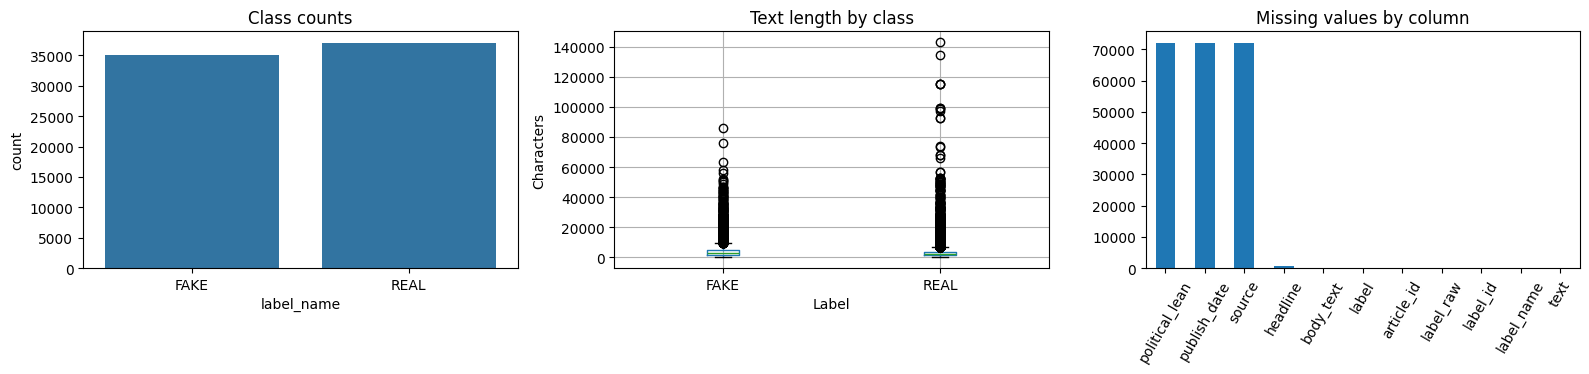

In [ ]:
print("Shape:", df.shape)
display(df.isna().sum().rename("missing_count").to_frame())
print("Exact text duplicates:", df.text.fillna("").str.lower().str.strip().duplicated().sum())
print("Average combined characters by class:")
display(df.assign(n_chars=df.text.str.len()).groupby("label_name").n_chars.describe())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=df, x="label_name", order=["FAKE","REAL"], ax=axes[0]); axes[0].set_title("Class counts")
df.assign(chars=df.text.str.len()).boxplot(column="chars", by="label_name", ax=axes[1]); axes[1].set_title("Text length by class"); axes[1].set_xlabel("Label"); axes[1].set_ylabel("Characters")
df.isna().sum().sort_values(ascending=False).plot(kind="bar", ax=axes[2]); axes[2].set_title("Missing values by column"); axes[2].tick_params(axis="x", rotation=60)
plt.suptitle(""); plt.tight_layout(); plt.show()

if df.source.notna().any():
    display(pd.crosstab(df.source.fillna("Unknown"), df.label_name, normalize="index").head(20))


## 4. Text cleanup and duplicate control

In [ ]:
def clean_text(value):
    if not isinstance(value, str): return ""
    value = html.unescape(value)
    value = re.sub(r"<[^>]+>", " ", value)
    value = re.sub(r"https?://\S+|www\.\S+", " URL ", value)
    value = re.sub(r"[\r\n\t]+", " ", value)
    value = re.sub(r"\s+", " ", value).strip()
    return value

df["text"] = df["text"].map(clean_text)
df = df[df.text.str.len() > 0].copy()
# Remove same normalized text before splitting. If identical text has conflicting labels,
# exclude all copies rather than allowing contradictory supervision or cross-split leakage.
df["dedupe_key"] = df.text.str.lower().str.replace(r"\W+", " ", regex=True).str.strip()
conflict_keys = df.groupby("dedupe_key").label_id.nunique()
conflict_keys = set(conflict_keys[conflict_keys > 1].index)
conflicts_removed = df.dedupe_key.isin(conflict_keys).sum()
df = df[~df.dedupe_key.isin(conflict_keys)].copy()
before = len(df)
df = df.drop_duplicates("dedupe_key", keep="first").reset_index(drop=True)
print("Conflicting-label rows removed:", conflicts_removed)
print("Repeated copies removed:", before-len(df))
print("Usable rows after cleanup:", len(df))


Conflicting-label rows removed: 0
Repeated copies removed: 8735
Usable rows after cleanup: 63399


### Split policy



In [ ]:
train_df, holdout_df = train_test_split(df, test_size=0.20, random_state=SEED, stratify=df.label_id)
val_df, test_df = train_test_split(holdout_df, test_size=0.50, random_state=SEED, stratify=holdout_df.label_id)
print({"train":len(train_df), "validation":len(val_df), "test":len(test_df)})
print(pd.DataFrame({"train":train_df.label_name.value_counts(normalize=True),
                    "validation":val_df.label_name.value_counts(normalize=True),
                    "test":test_df.label_name.value_counts(normalize=True)}).round(3))


{'train': 50719, 'validation': 6340, 'test': 6340}
            train  validation   test
label_name                          
FAKE        0.545       0.544  0.544
REAL        0.455       0.456  0.456


## 5. Tokenization and Hugging Face model

In [ ]:
MODEL_NAME = "distilbert/distilbert-base-uncased"
MAX_LENGTH = 384  # adjust for GPU memory; increase only after checking truncation needs
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
id2label = {0:"FAKE", 1:"REAL"}; label2id = {v:k for k,v in id2label.items()}

class NewsDataset(torch.utils.data.Dataset):
    def __init__(self, frame):
        self.texts = frame.text.tolist()
        self.labels = frame.label_id.astype(int).tolist()
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        item = tokenizer(self.texts[i], truncation=True, max_length=MAX_LENGTH)
        item["labels"] = self.labels[i]
        return item

train_ds, val_ds, test_ds = NewsDataset(train_df), NewsDataset(val_df), NewsDataset(test_df)
print("Tokenizer:", MODEL_NAME, "| max length:", MAX_LENGTH)
print("One tokenized example length:", len(tokenizer(train_df.text.iloc[0], truncation=True, max_length=MAX_LENGTH)["input_ids"]))


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer: distilbert/distilbert-base-uncased | max length: 384
One tokenized example length: 119


In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2, id2label=id2label, label2id=label2id
)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = torch.softmax(torch.tensor(logits), dim=-1).numpy()[:, 1]
    preds = (probs >= 0.5).astype(int)
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="binary", zero_division=0)
    metrics = {"accuracy":accuracy_score(labels,preds), "precision_real":p, "recall_real":r, "f1_real":f1}
    if len(np.unique(labels)) == 2: metrics["roc_auc"] = roc_auc_score(labels, probs)
    return metrics

training_args = TrainingArguments(
    output_dir="./results/fake-news-distilbert",
    num_train_epochs=3,
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_real",
    greater_is_better=True,
    logging_strategy="steps", logging_steps=100,
    save_total_limit=2,
    report_to="none",
    seed=SEED,
    fp16=torch.cuda.is_available(),
)
trainer = Trainer(model=model, args=training_args, train_dataset=train_ds,
                  eval_dataset=val_ds,
                  data_collator=data_collator, compute_metrics=compute_metrics)
print("Ready to fine-tune. No performance numbers exist until trainer.train() completes.")


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Ready to fine-tune. No performance numbers exist until trainer.train() completes.


In [ ]:

train_result = trainer.train()
print(train_result.metrics)


Epoch,Training Loss,Validation Loss,Accuracy,Precision Real,Recall Real,F1 Real,Roc Auc
1,0.043168,0.025511,0.993533,0.992731,0.993075,0.992903,0.999827
2,0.017705,0.027966,0.993849,0.994446,0.992036,0.993240,0.999820
3,0.000058,0.038189,0.994795,0.994801,0.993767,0.994284,0.999814


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': 2063.1164, 'train_samples_per_second': 73.751, 'train_steps_per_second': 9.219, 'total_flos': 1.5116759364592608e+16, 'train_loss': 0.02742435811340579, 'epoch': 3.0}


## 6. Final evaluation on the held-out test set

Training Loss,Validation Loss,Epoch,Accuracy,Precision Real,Recall Real,F1 Real,Roc Auc
0.000058,0.040831,3,0.993849,0.992395,0.994114,0.993254,0.999676


Measured held-out metrics from this run: {'test_loss': 0.04083070531487465, 'test_accuracy': 0.9938485804416404, 'test_precision_real': 0.9923954372623575, 'test_recall_real': 0.9941135734072022, 'test_f1_real': 0.9932537623248573, 'test_roc_auc': 0.9996757570383542}
              precision    recall  f1-score   support

        FAKE       1.00      0.99      0.99      3452
        REAL       0.99      0.99      0.99      2888

    accuracy                           0.99      6340
   macro avg       0.99      0.99      0.99      6340
weighted avg       0.99      0.99      0.99      6340



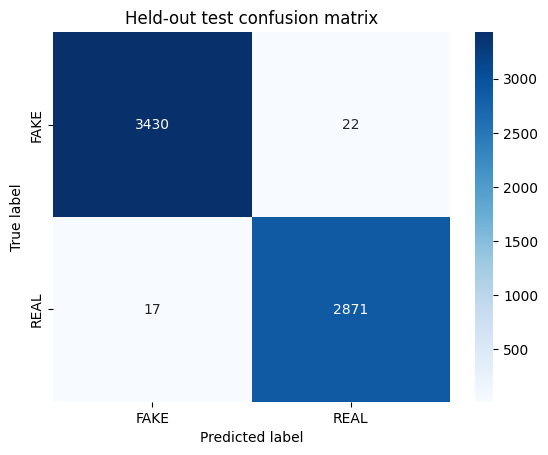

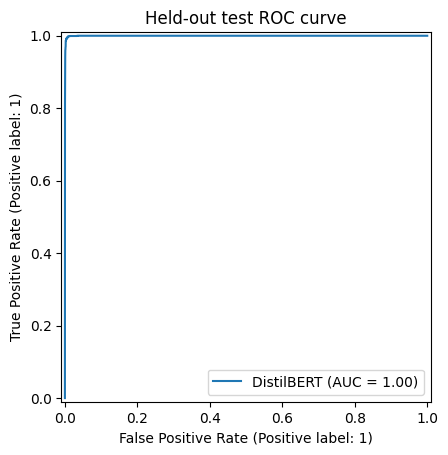

In [ ]:
# The test set is evaluated once after choosing the best checkpoint on validation F1.
test_metrics = trainer.evaluate(test_ds, metric_key_prefix="test")
pred_output = trainer.predict(test_ds, metric_key_prefix="test")
test_probs = torch.softmax(torch.tensor(pred_output.predictions), dim=-1).numpy()[:,1]
test_pred = (test_probs >= 0.5).astype(int)
y_test = test_df.label_id.to_numpy()
print("Measured held-out metrics from this run:", test_metrics)
print(classification_report(y_test, test_pred, target_names=["FAKE","REAL"], zero_division=0))

cm = confusion_matrix(y_test, test_pred, labels=[0,1])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["FAKE","REAL"], yticklabels=["FAKE","REAL"])
plt.xlabel("Predicted label"); plt.ylabel("True label"); plt.title("Held-out test confusion matrix"); plt.show()
if len(np.unique(y_test)) == 2:
    RocCurveDisplay.from_predictions(y_test, test_probs, name="DistilBERT")
    plt.title("Held-out test ROC curve"); plt.show()


## 7. Error analysis

In [ ]:
errors = test_df[["article_id","headline","body_text","source","publish_date","political_lean","label_name","text"]].copy()
errors["predicted"] = [id2label[int(x)] for x in test_pred]
errors["p_real"] = test_probs
errors = errors[errors.label_name != errors.predicted].sort_values("p_real")
print("Misclassified test examples:", len(errors))
display(errors[["article_id","headline","source","publish_date","political_lean","label_name","predicted","p_real"]].head(20))


Misclassified test examples: 39


,article_id,headline,source,publish_date,political_lean,label_name,predicted,p_real
46759,row_51227,"Hillary's Secretary of State After 9/11: ""Send...",<NA>,<NA>,<NA>,REAL,FAKE,0.000073
36017,row_38608,Wells Fargo or the Federal Reserve: Who’s the ...,<NA>,<NA>,<NA>,REAL,FAKE,0.000102
56814,row_63657,Democrats Contaminate Cliven Bundy Jury Pool w...,<NA>,<NA>,<NA>,REAL,FAKE,0.000726
30587,row_32415,You’re Being Fooled: The Problem With ‘Alterna...,<NA>,<NA>,<NA>,REAL,FAKE,0.000778
35332,row_37816,Comments circulating about the Republican pres...,<NA>,<NA>,<NA>,REAL,FAKE,0.001528
46966,row_51482,"""Nancy Reagan's Last Words """"Do Not Vote For D...",<NA>,<NA>,<NA>,REAL,FAKE,0.002337
9639,row_9799,Russia Has Shot From 124th to 40th in 'Ease of...,<NA>,<NA>,<NA>,REAL,FAKE,0.002856
34520,row_36892,4 New Polls Suggest That Republicans Are On Th...,<NA>,<NA>,<NA>,REAL,FAKE,0.002929
30015,row_31772,Tsunami Hits New Zealand After Massive 7.8 Ear...,<NA>,<NA>,<NA>,REAL,FAKE,0.004207
25906,row_27187,“Rigged To Deny Trump”: Are They Stealing Thes...,<NA>,<NA>,<NA>,REAL,FAKE,0.005609


## 8. Optional LIME explanation for one prediction

In [ ]:
# Optional. Install lime if needed: %pip install -q lime
# LIME explanations are local approximations that can be unstable; they do not prove causation.
RUN_LIME = False
if RUN_LIME:
    from lime.lime_text import LimeTextExplainer
    device = next(trainer.model.parameters()).device
    def predict_proba(texts):
        batch = tokenizer(list(texts), padding=True, truncation=True, max_length=MAX_LENGTH, return_tensors="pt").to(device)
        with torch.no_grad(): logits = trainer.model(**batch).logits
        return torch.softmax(logits, dim=-1).cpu().numpy()
    explainer = LimeTextExplainer(class_names=["FAKE","REAL"])
    sample_text = test_df.text.iloc[0]
    explanation = explainer.explain_instance(sample_text, predict_proba, num_features=10, labels=[0,1])
    display(explanation.as_list(label=int(test_pred[0])))


## 9. Save model and tokenizer

In [ ]:
SAVE_DIR = Path("saved_fake_news_model")
trainer.save_model(str(SAVE_DIR))
tokenizer.save_pretrained(str(SAVE_DIR))
print("Saved model files to:", SAVE_DIR.resolve())


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved model files to: /content/saved_fake_news_model


In [ ]:
import shutil
model_zip = shutil.make_archive(
    "saved_fake_news_model",
    "zip",
    root_dir=".",
    base_dir=str(SAVE_DIR),
)
print("Model archive created:", model_zip)

# In Google Colab this opens a download for your computer.
# In local Jupyter, the ZIP is saved in the notebook's current folder.
try:
    from google.colab import files
    files.download(model_zip)
except ImportError:
    print("Download/copy saved_fake_news_model.zip from the current folder.")

Model archive created: /content/saved_fake_news_model.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Inference on new text

In [ ]:
# Reload from the saved folder (or replace with a trusted model path).
inference_tokenizer = AutoTokenizer.from_pretrained(SAVE_DIR)
inference_model = AutoModelForSequenceClassification.from_pretrained(SAVE_DIR)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
inference_model.to(device).eval()

def classify_news(headline, body_text):
    text = clean_text(f"{headline or ''} {body_text or ''}")
    inputs = inference_tokenizer(text, return_tensors="pt", truncation=True, max_length=MAX_LENGTH).to(device)
    with torch.no_grad(): probs = torch.softmax(inference_model(**inputs).logits, dim=-1)[0].cpu().numpy()
    pred_id = int(np.argmax(probs))
    return {"predicted_label": id2label[pred_id], "p_fake": float(probs[0]), "p_real": float(probs[1]),
            "notice": "Model output is not fact verification; require human review."}

example = classify_news("NASA’s Perseverance Rover Lands on Mars", "NASA’s Perseverance rover landed in Mars’s Jezero Crater on February 18, 2021, after a journey of nearly seven months. The mission was designed to study the planet’s geology and search for signs of ancient microbial life. The rover also carried the Ingenuity helicopter, which later completed the first powered, controlled flight on another planet.")
print(example)


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

{'predicted_label': 'REAL', 'p_fake': 6.06969406362623e-05, 'p_real': 0.9999393224716187, 'notice': 'Model output is not fact verification; require human review.'}
